# [CS303] Practice 11 - Implementing a Neural Network with NumPy

In this practice, you will implement and train a fully connected neural network using only NumPy. The model classifies handwritten digits from a 10,000-image subset of MNIST.

## Required tasks

1. Convert integer labels to one-hot vectors.
2. Initialize all weights and biases.
3. Implement a numerically stable softmax function.
4. Implement forward propagation.
5. Implement cross-entropy loss with L2 regularization.
6. Implement backpropagation for all three weight layers.
7. Pass the unit tests and the numerical gradient check.
8. Train the model and discuss its learning curve and mistakes.

You do **not** need TensorFlow, PyTorch, or scikit-learn. Do not change the function names or parameter lists because the tests call them directly.



## Practice Deadline and Checking Policy

The score for this practice is determined by **when you complete the in-person check during your scheduled lab session**. Please follow the schedule for your own lab group.

| Lab Group | Full Credit (100%) | Late Check (50%) | After the 50% Deadline |
|---|---|---|---|
| **Wednesday** | Dec. 02 or Dec. 09 | Dec. 16 | 0% |
| **Thursday** | Dec. 03 or Dec. 10 | Dec. 17 | 0% |
| **Friday** | Dec. 04 or Dec. 11 | Dec. 18 | 0% |


You have **three lab sessions** to complete the practice and have your work checked for full credit (100%). If you miss all sessions, you may still receive 50% credit by completing the in-person check during your group's late-check session. Any check after the specified 50% deadline will receive 0 points.

**Important:** Your score is determined by the date of your **in-person check**, not the date when you finish the code.

## Onsite Check Requirements

To pass the onsite check, you must demonstrate the following to your TA or lab instructor:

1. **Completed implementation and tests**
   - Complete all six required TODO functions.
   - Run the notebook from the beginning and show that all unit tests and the numerical gradient check pass.

2. **Dataset and network structure**
   - Explain how `data.pkl` stores the training and test data.
   - Explain the training, validation, and test split.
   - Explain the shapes in the `784 -> 300 -> 100 -> 10` network.

3. **Forward propagation**
   - Explain Xavier initialization, including `fan_in` and `fan_out`.
   - Explain the roles of ReLU, logits, stable softmax, and class probabilities.

4. **Loss and backpropagation**
   - Explain cross-entropy loss and L2 regularization.
   - Explain the main steps from $\delta_3$ to $\delta_2$ and $\delta_1$.

5. **Training and evaluation**
   - Show the training and validation curves, final test accuracy, confusion matrix, and example mistakes.
   - Answer one or two conceptual questions selected by the lab tutor or SA.

### Evaluation Criteria

Your work will be assessed based on:

- clear understanding of the code rather than blind copy-paste;
- correct implementation of forward propagation and backpropagation;
- correct matrix shapes and numerically stable computations;
- successful unit tests and numerical gradient checking;
- meaningful interpretation of training and evaluation results;
- reasonable computational efficiency.


## Learning objectives

After this practice, you should be able to:

- track matrix shapes through a multilayer network;
- explain why ReLU is used in hidden layers and softmax in the output layer;
- connect cross-entropy loss to multiclass classification;
- derive gradients with the chain rule;
- distinguish training, validation, and test evaluation;
- use a numerical gradient check to find errors in backpropagation.


## 1. Network and lab PPT notation

We keep the architecture and zero-based layer numbering used in the lab PPT:

$$784 \rightarrow 300 \rightarrow 100 \rightarrow 10$$

The input is layer 0. Therefore, the first hidden layer uses $W^{(1)}$ and
$b^{(1)}$, while the output layer uses $W^{(3)}$ and $b^{(3)}$:

$$x^{(0)} \rightarrow a^{(1)} \rightarrow x^{(1)}
\rightarrow a^{(2)} \rightarrow x^{(2)}
\rightarrow a^{(3)} \rightarrow x^{(3)}=\hat{y}.$$

For a mini-batch of size $N$, this notebook stores examples as rows. In the
Python code, `batch_size` represents this $N$. For example,
`batch_size = 128` means that one mini-batch contains $N = 128$ examples.

| Quantity | Shape | Meaning |
|---|---:|---|
| `x0` | `(N, 784)` | flattened input images |
| `W1`, `b1` | `(784, 300)`, `(1, 300)` | input to hidden layer 1 |
| `W2`, `b2` | `(300, 100)`, `(1, 100)` | hidden layer 1 to hidden layer 2 |
| `W3`, `b3` | `(100, 10)`, `(1, 10)` | hidden layer 2 to output layer |
| `x3` | `(N, 10)` | predicted class probabilities |

With the row-vector convention, an affine layer is `x @ W + b`. NumPy
broadcasts the one-row bias across the mini-batch. The row-vector formulas
are transposes of column-vector formulas, but the layer indices match the
lab PPT exactly.


In [60]:
from typing import Dict, Iterator, List, Tuple
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np

Array = np.ndarray
Parameters = Dict[str, Array]

SEED = 42
rng = np.random.RandomState(SEED)
np.set_printoptions(precision=4, suppress=True)


## 2. Load and split the data

Pixel values are integers from 0 to 255. Dividing by 255 converts them to `[0, 1]`. We keep 2,000 training examples as a validation set and leave the supplied test set untouched until final evaluation.


In [61]:
with open("data.pkl", "rb") as file:
    train_images_raw, train_labels_raw, test_images_raw, test_labels = pickle.load(
        file, encoding="latin1"
    )

all_images = train_images_raw.astype(np.float64) / 255.0
test_images = test_images_raw.astype(np.float64) / 255.0
all_labels = train_labels_raw.astype(np.int64)
test_labels = test_labels.astype(np.int64)

split_rng = np.random.RandomState(SEED)
indices = split_rng.permutation(all_images.shape[0])
validation_indices = indices[:2000]
training_indices = indices[2000:]

train_images = all_images[training_indices]
train_labels = all_labels[training_indices]
validation_images = all_images[validation_indices]
validation_labels = all_labels[validation_indices]

print("Training:", train_images.shape, train_labels.shape)
print("Validation:", validation_images.shape, validation_labels.shape)
print("Test:", test_images.shape, test_labels.shape)
print("Pixel range: [{:.1f}, {:.1f}]".format(train_images.min(), train_images.max()))


Training: (8000, 784) (8000,)
Validation: (2000, 784) (2000,)
Test: (1000, 784) (1000,)
Pixel range: [0.0, 1.0]


## 3. One-hot encoding

Cross-entropy compares one probability distribution with another. The label `7` therefore becomes `[0, 0, 0, 0, 0, 0, 0, 1, 0, 0]`.


In [62]:
def one_hot(labels: Array, num_classes: int) -> Array:
    """Convert integer labels into a one-hot matrix.

    Args:
        labels: Integer array with shape `(n_samples,)`.
        num_classes: Total number of classes.

    Returns:
        Float array with shape `(n_samples, num_classes)`.
    """
    # TODO 1: Create the zero matrix and place 1 at each correct class index.
    raise NotImplementedError("Complete TODO 1")


In [63]:
encoded_test = one_hot(np.array([0, 2, 1]), 3)
expected_test = np.array([[1.0, 0.0, 0.0],
                          [0.0, 0.0, 1.0],
                          [0.0, 1.0, 0.0]])
assert np.array_equal(encoded_test, expected_test)
print("One-hot encoding test passed.")


One-hot encoding test passed.


## 4. Parameter initialization

Xavier uniform initialization samples a weight matrix with `fan_in` inputs
and `fan_out` outputs from

$$U\left[-\sqrt{\frac{6}{fan\_in+fan\_out}},
\sqrt{\frac{6}{fan\_in+fan\_out}}\right].$$

The dictionary keys follow the lab PPT layer numbers: `W1`, `b1`, `W2`,
`b2`, `W3`, and `b3`. Biases start at zero.

### What do `fan_in` and `fan_out` mean?

The word *fan* describes how connections spread out like a fan between two layers. `fan_in` is the number of values entering a layer, and `fan_out` is the number of values leaving it. In Python, underscores are used because `fan-in` would be interpreted as subtraction.

For example, the first weight matrix has shape `(784, 300)`. It connects 784 input pixels to 300 hidden neurons, so `fan_in = 784` and `fan_out = 300`. The next matrix has shape `(300, 100)`, so its values are `fan_in = 300` and `fan_out = 100`. Xavier initialization uses both numbers to choose a suitable range for the initial weights. This helps prevent activations from becoming extremely large or extremely small at the beginning of training.


In [64]:
def initialize_parameters(
    layer_sizes: List[int], rng: np.random.RandomState
) -> Parameters:
    """Initialize weights and biases using the lab PPT layer numbers.

    Args:
        layer_sizes: Units in layers 0, 1, 2, and 3.
        rng: Seeded NumPy random generator for reproducibility.

    Returns:
        Dictionary containing `W1`, `b1`, `W2`, `b2`, `W3`, and `b3`.
    """

    # TODO 2: Initialize W1-W3 with Xavier uniform values and b1-b3 with zeros.
    # Hint: loop through layers 1, 2, and 3 in layer_sizes.
    # fan_in is the previous layer size; fan_out is the current layer size.
    raise NotImplementedError("Complete TODO 2")


In [65]:
shape_test = initialize_parameters([4, 3, 2, 2], np.random.RandomState(0))
assert shape_test["W1"].shape == (4, 3)
assert shape_test["b1"].shape == (1, 3)
assert shape_test["W2"].shape == (3, 2)
assert shape_test["W3"].shape == (2, 2)
assert np.all(shape_test["b1"] == 0.0)
print("Parameter initialization tests passed.")


Parameter initialization tests passed.


## 5. Activation functions

ReLU keeps positive inputs and replaces negative inputs with zero. Its derivative is 1 where the pre-activation is positive and 0 elsewhere.

Softmax converts each row of logits into probabilities. Directly computing `exp(logits)` may overflow, so subtract the largest value in each row first. This changes neither the resulting probabilities nor the predicted class.


In [66]:
def relu(values: Array) -> Array:
    """Apply ReLU without modifying the input array."""
    return np.maximum(values, 0.0)


def relu_grad(pre_activations: Array) -> Array:
    """Return the elementwise derivative of ReLU."""
    return (pre_activations > 0.0).astype(np.float64)


def softmax(logits: Array) -> Array:
    """Convert a `(batch_size, num_classes)` logit matrix to probabilities."""
    # TODO 3: Subtract the largest logit in each row before calling np.exp.
    raise NotImplementedError("Complete TODO 3")


In [80]:
large_logits = np.array([[1000.0, 1001.0, 999.0], [-1000.0, -999.0, -1001.0]])
probability_test = softmax(large_logits)
probability_test

array([[0.2447, 0.6652, 0.09  ],
       [0.2447, 0.6652, 0.09  ]])

In [ ]:
assert np.all(np.isfinite(probability_test))
assert np.allclose(probability_test.sum(axis=1), 1.0)
assert np.array_equal(np.argmax(probability_test, axis=1), np.array([1, 1]))
print("Stable softmax tests passed.")


## 6. Forward propagation

The variable names below match the lab PPT:

$$a^{(1)}=x^{(0)}W^{(1)}+b^{(1)}, \quad x^{(1)}=ReLU(a^{(1)})$$
$$a^{(2)}=x^{(1)}W^{(2)}+b^{(2)}, \quad x^{(2)}=ReLU(a^{(2)})$$
$$a^{(3)}=x^{(2)}W^{(3)}+b^{(3)}, \quad x^{(3)}=softmax(a^{(3)})$$

Store the intermediate arrays because backpropagation needs $a^{(1)}$ and
$a^{(2)}$ for the ReLU derivatives.


In [ ]:
def forward(x0: Array, params: Parameters) -> Tuple[Array, Dict[str, Array]]:
    """Run forward propagation through layers 1, 2, and 3.

    Args:
        x0: Input mini-batch with shape `(batch_size, 784)`.
        params: Parameters named according to their destination layer.

    Returns:
        `(x3, cache)`, where `x3` contains class probabilities and `cache`
        contains the lab PPT variables required by backward().
    """

    # TODO 4: Compute a1, x1, a2, x2, a3, and x3 in lab PPT order.
    # Store all seven arrays, including x0, in cache.
    # cache = {"x0": x0, "a1": a1, "x1": x1,
    #             "a2": a2, "x2": x2, "a3": a3, "x3": x3}
    
    raise NotImplementedError("Complete TODO 4")


In [69]:
tiny_params = initialize_parameters([4, 5, 3, 2], np.random.RandomState(1))
tiny_x0 = np.array([[1.0, 0.0, -1.0, 2.0], [0.5, -0.5, 1.0, 0.0]])
tiny_x3, tiny_cache = forward(tiny_x0, tiny_params)
assert tiny_x3.shape == (2, 2)
assert tiny_cache["a1"].shape == (2, 5)
assert tiny_cache["x1"].shape == (2, 5)
assert tiny_cache["a2"].shape == (2, 3)
assert tiny_cache["x2"].shape == (2, 3)
assert np.allclose(tiny_x3.sum(axis=1), 1.0)
print("Forward propagation tests passed.")


Forward propagation tests passed.


## 7. Cross-entropy with L2 regularization

For a batch of $N$ examples, the objective is

$$L=-\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K}t_{ik}\log p_{ik}
+\frac{\lambda}{2}\sum_l\lVert W_l\rVert_F^2.$$

The subscript $F$ denotes the Frobenius norm. For a weight matrix $W$,
$$\lVert W\rVert_F^2=\sum_i\sum_j W_{ij}^2,$$
which is the sum of the squares of all entries in the matrix.

Biases are not regularized. Add a small constant inside `log` to handle probabilities that round to zero.


In [70]:
def compute_loss(
    probabilities: Array,
    targets: Array,
    params: Parameters,
    l2: float,
) -> float:
    """Return mean cross-entropy plus L2 regularization.

    Args:
        probabilities: Model output with shape `(batch_size, num_classes)`.
        targets: One-hot labels with the same shape.
        params: Model parameters; only weight matrices are regularized.
        l2: Non-negative regularization strength; this is lambda in the formula.
    """
    # TODO 5: Compute mean cross-entropy plus 0.5 * l2 * sum(W * W).
    # Add a small epsilon inside log to avoid log(0).
    raise NotImplementedError("Complete TODO 5")


In [71]:
perfect = np.array([[0.99, 0.01], [0.02, 0.98]])
wrong = np.array([[0.01, 0.99], [0.98, 0.02]])
targets_test = np.eye(2)
zero_weights = {"W1": np.zeros((2, 2)), "b1": np.zeros((1, 2))}
assert compute_loss(perfect, targets_test, zero_weights, 0.0) < compute_loss(
    wrong, targets_test, zero_weights, 0.0
)
assert np.isfinite(compute_loss(np.array([[1.0, 0.0]]), np.array([[1.0, 0.0]]), zero_weights, 0.0))
print("Loss tests passed.")


Loss tests passed.


## 8. Backpropagation in lab PPT order

Let $N$ be the number of examples in the mini-batch. In the code,
`batch_size` is this $N$, and `targets.shape[0]` obtains the actual $N$ for
the current mini-batch. For softmax with cross-entropy, the output delta is

$$\delta_3=\frac{\partial L}{\partial a^{(3)}}
=\frac{x^{(3)}-t}{N}.$$

Then move from layer 3 to layer 1:

$$\frac{\partial L}{\partial W^{(3)}}=(x^{(2)})^T\delta_3
+\lambda W^{(3)}, \qquad
\frac{\partial L}{\partial b^{(3)}}=\sum_i\delta_{3,i}$$

$$\delta_2=(\delta_3(W^{(3)})^T)\circ ReLU'(a^{(2)})$$
$$\frac{\partial L}{\partial W^{(2)}}=(x^{(1)})^T\delta_2
+\lambda W^{(2)}$$

$$\delta_1=(\delta_2(W^{(2)})^T)\circ ReLU'(a^{(1)})$$
$$\frac{\partial L}{\partial W^{(1)}}=(x^{(0)})^T\delta_1
+\lambda W^{(1)}$$

The division by $N$ is already included in $\delta_3$, so do not divide
later gradients a second time. Bias gradients are summed over rows. L2
regularization applies to weights but not biases.


In [72]:
def backward(
    targets: Array,
    params: Parameters,
    cache: Dict[str, Array],
    l2: float,
) -> Parameters:
    """Compute gradients using delta3, delta2, and delta1.

    Args:
        targets: One-hot labels with shape `(batch_size, 10)`.
        params: Current `W1`-`W3` and `b1`-`b3` values.
        cache: Lab PPT variables returned by forward().
        l2: L2 regularization strength; this is lambda in the formulas.

    Returns:
        Gradients with the same keys and shapes as `params`.
    """

    # TODO 6: Compute delta3, delta2, and delta1 in that order.
    # Then compute gradients for W3/b3, W2/b2, and W1/b1.
    # Average once through delta3; regularize weights but not biases.
    raise NotImplementedError("Complete TODO 6")


### Numerical gradient check

Backpropagation gives an **analytical gradient** by applying the chain rule. A numerical gradient check independently estimates the same gradient from changes in the loss. If the two values are very close, the backpropagation implementation is likely correct.

For one parameter $\theta$, slightly increase and decrease its value by a small number $\epsilon$:

$$\frac{\partial L}{\partial \theta}\approx
\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}.$$

This is called the **central difference approximation**. The check follows four steps:

1. Compute the analytical gradients with `backward()`.
2. Temporarily replace one parameter by $\theta+\epsilon$ and compute `plus`.
3. Temporarily replace it by $\theta-\epsilon$ and compute `minus`.
4. Restore the original parameter and compare the numerical and analytical gradients.

The comparison uses relative error:

$$\text{relative error}=
\frac{|g_{numerical}-g_{analytical}|}
{\max(10^{-8}, |g_{numerical}|+|g_{analytical}|)}.$$

Relative error is more useful than absolute error when gradients are very small. In this practice, an error below $10^{-5}$ passes the check. A very small error provides strong evidence that the checked gradients are correct, but it does not prove that every parameter, the training settings, or the final model is correct.

Numerical gradients are too slow for training because each checked parameter requires two additional forward passes. Therefore, the code uses a small test network and checks only one representative entry from each weight and bias array.


In [73]:
def gradient_check(
    params: Parameters,
    x0: Array,
    targets: Array,
    l2: float,
    epsilon: float = 1e-5,
) -> float:
    """Compare analytical and numerical gradients at selected entries.

    Args:
        params: Parameters of a small network used only for checking.
        x0: Small input batch.
        targets: One-hot labels for the input batch.
        l2: L2 regularization strength; this is lambda in the formulas.
        epsilon: Small parameter change used by the central difference.

    Returns:
        The largest relative error among the selected parameter entries.
    """
    # Backpropagation provides the analytical gradients.
    x3, cache = forward(x0, params)
    analytic = backward(targets, params, cache, l2)

    # Checking a few representative entries is much faster than checking all parameters.
    checks = [("W1", (0, 0)), ("b1", (0, 1)),
              ("W2", (1, 0)), ("b2", (0, 0)),
              ("W3", (0, 1)), ("b3", (0, 1))]
    errors = []

    for name, index in checks:
        # Save the original value so that this check does not change the model.
        original = params[name][index]

        # Evaluate L(theta + epsilon).
        params[name][index] = original + epsilon
        plus = compute_loss(forward(x0, params)[0], targets, params, l2)

        # Evaluate L(theta - epsilon).
        params[name][index] = original - epsilon
        minus = compute_loss(forward(x0, params)[0], targets, params, l2)

        # Always restore theta before checking another parameter.
        params[name][index] = original

        # Central difference estimates the gradient without using backpropagation.
        numerical = (plus - minus) / (2.0 * epsilon)
        expected = analytic[name][index]

        # Relative error remains informative when the gradients are close to zero.
        relative_error = abs(numerical - expected) / max(
            1e-8, abs(numerical) + abs(expected)
        )
        errors.append(relative_error)

    return float(max(errors))


# Use a tiny network and batch so that the numerical check runs quickly.
check_params = initialize_parameters([4, 5, 4, 3], np.random.RandomState(3))
check_x0 = np.random.RandomState(4).normal(size=(5, 4))
check_targets = one_hot(np.array([0, 1, 2, 1, 0]), 3)
maximum_error = gradient_check(check_params, check_x0, check_targets, l2=0.01)
print("Maximum relative gradient error: {:.2e}".format(maximum_error))
assert maximum_error < 1e-5
print("Backpropagation gradient check passed.")


Maximum relative gradient error: 8.82e-10
Backpropagation gradient check passed.


## 9. Mini-batch training

The training loop below is supplied. Each epoch shuffles the training set, updates the parameters using mini-batch gradient descent, then measures training and validation performance. The test set remains unused during model development.

### Why use mini-batches?

There are three common ways to choose the data for one parameter update:

| Method | Examples per update | Main characteristic |
|---|---:|---|
| Batch gradient descent | the entire training set | stable gradient, but each update is expensive |
| Stochastic gradient descent | 1 | very frequent updates, but the gradient is noisy |
| Mini-batch gradient descent | a small group | balances efficiency and gradient stability |

Mini-batch training is useful for this practice for four reasons:

1. **Efficient matrix operations.** With `batch_size = 128`, the input `x0` has shape `(128, 784)`. NumPy can process these 128 images together with matrix multiplication instead of using a Python loop.
2. **More frequent updates.** The training set contains 8,000 examples, so one epoch performs $\lceil 8000/128 \rceil=63$ parameter updates instead of only one full-batch update.
3. **More stable than one-sample updates.** Averaging information from several examples reduces the influence of an unusual or ambiguous handwritten digit.
4. **Lower memory use.** The network only needs to store intermediate values such as `a1`, `x1`, `a2`, and `x2` for the current mini-batch.

The mathematical symbol $N$ used earlier means the number of examples in the **current** mini-batch. In the code, this value is called `batch_size`. The final mini-batch may contain fewer than 128 examples, so backpropagation obtains its actual $N$ from `targets.shape[0]`.

### Why shuffle every epoch?

Before creating mini-batches, `rng.permutation(...)` randomly changes the sample order. Without shuffling, the same examples would repeatedly appear together, and a mini-batch might contain an unrepresentative group of digits. Shuffling creates different groups across epochs and helps reduce ordering bias.

The choice `batch_size = 128` is a practical compromise: it is large enough for efficient matrix operations and stable gradients, but small enough to provide many updates per epoch and modest memory use.


In [74]:
def iterate_minibatches(
    images: Array,
    labels: Array,
    batch_size: int,
    rng: np.random.RandomState,
) -> Iterator[Tuple[Array, Array]]:
    """Yield shuffled mini-batches, including the final smaller batch."""
    order = rng.permutation(images.shape[0])
    for start in range(0, images.shape[0], batch_size):
        batch_indices = order[start:start + batch_size]
        yield images[batch_indices], labels[batch_indices]


def predict(images: Array, params: Parameters) -> Array:
    """Return the most probable class for each image."""
    probabilities, _ = forward(images, params)
    return np.argmax(probabilities, axis=1)


def accuracy(images: Array, labels: Array, params: Parameters) -> float:
    """Return the fraction of correctly classified images."""
    return float(np.mean(predict(images, params) == labels))


def update_parameters(
    params: Parameters, gradients: Parameters, learning_rate: float
) -> None:
    """Apply one gradient-descent update in place."""
    for name in params:
        params[name] -= learning_rate * gradients[name]


def train_network(
    train_x: Array,
    train_y: Array,
    validation_x: Array,
    validation_y: Array,
    layer_sizes: List[int],
    epochs: int = 15,
    batch_size: int = 128,
    learning_rate: float = 0.12,
    l2: float = 1e-4,
    seed: int = 42,
) -> Tuple[Parameters, Dict[str, List[float]]]:
    """Train a fully connected neural network with mini-batch gradient descent."""
    training_rng = np.random.RandomState(seed)
    params = initialize_parameters(layer_sizes, training_rng)
    history = {"loss": [], "train_accuracy": [], "validation_accuracy": []}

    for epoch in range(epochs):
        batch_losses = []
        for batch_x, batch_y in iterate_minibatches(
            train_x, train_y, batch_size, training_rng
        ):
            targets = one_hot(batch_y, layer_sizes[-1])
            probabilities, cache = forward(batch_x, params)
            batch_losses.append(compute_loss(probabilities, targets, params, l2))
            gradients = backward(targets, params, cache, l2)
            update_parameters(params, gradients, learning_rate)

        epoch_loss = float(np.mean(batch_losses))
        train_acc = accuracy(train_x, train_y, params)
        validation_acc = accuracy(validation_x, validation_y, params)
        history["loss"].append(epoch_loss)
        history["train_accuracy"].append(train_acc)
        history["validation_accuracy"].append(validation_acc)
        print(
            "Epoch {:2d}/{:2d} - loss: {:.4f} - train acc: {:.3f} - val acc: {:.3f}".format(
                epoch + 1, epochs, epoch_loss, train_acc, validation_acc
            )
        )

    return params, history


In [75]:
start_time = time.perf_counter()
parameters, history = train_network(
    train_images,
    train_labels,
    validation_images,
    validation_labels,
    layer_sizes=[784, 300, 100, 10],
    epochs=18,
    batch_size=128,
    learning_rate=0.1,
    l2=1e-4,
    seed=SEED,
)
elapsed = time.perf_counter() - start_time
print("Training time: {:.1f} seconds".format(elapsed))


Epoch  1/18 - loss: 1.0815 - train acc: 0.874 - val acc: 0.882
Epoch  2/18 - loss: 0.4591 - train acc: 0.895 - val acc: 0.896
Epoch  3/18 - loss: 0.3597 - train acc: 0.898 - val acc: 0.896
Epoch  4/18 - loss: 0.3164 - train acc: 0.914 - val acc: 0.915
Epoch  5/18 - loss: 0.2824 - train acc: 0.930 - val acc: 0.919
Epoch  6/18 - loss: 0.2593 - train acc: 0.918 - val acc: 0.908
Epoch  7/18 - loss: 0.2367 - train acc: 0.939 - val acc: 0.930
Epoch  8/18 - loss: 0.2222 - train acc: 0.953 - val acc: 0.940
Epoch  9/18 - loss: 0.2040 - train acc: 0.954 - val acc: 0.943
Epoch 10/18 - loss: 0.1909 - train acc: 0.940 - val acc: 0.926
Epoch 11/18 - loss: 0.1802 - train acc: 0.969 - val acc: 0.948
Epoch 12/18 - loss: 0.1637 - train acc: 0.964 - val acc: 0.946
Epoch 13/18 - loss: 0.1610 - train acc: 0.968 - val acc: 0.947
Epoch 14/18 - loss: 0.1488 - train acc: 0.973 - val acc: 0.947
Epoch 15/18 - loss: 0.1401 - train acc: 0.957 - val acc: 0.940
Epoch 16/18 - loss: 0.1315 - train acc: 0.975 - val acc

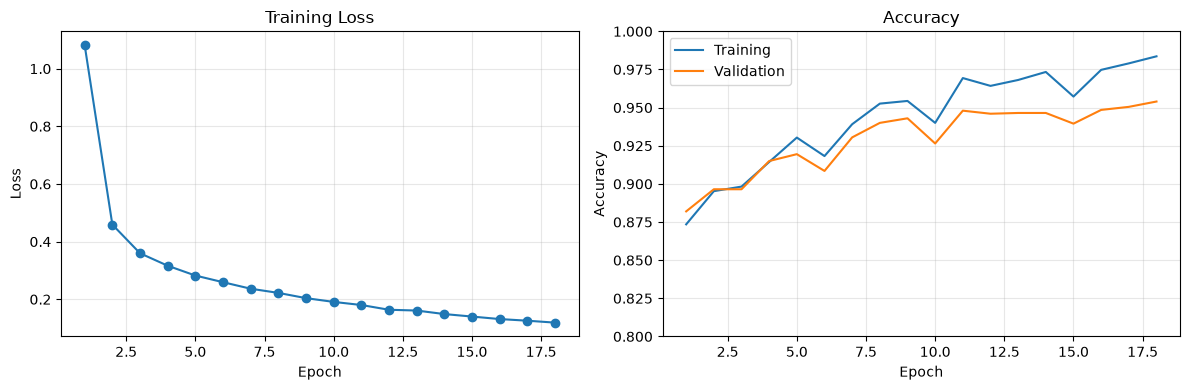

In [76]:
epochs_axis = np.arange(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_axis, history["loss"], marker="o")
axes[0].set(title="Training Loss", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_axis, history["train_accuracy"], label="Training")
axes[1].plot(epochs_axis, history["validation_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0.8, 1.0))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Final test evaluation

We now use the untouched test set once. The confusion matrix uses rows for true labels and columns for predicted labels.


Final test accuracy: 93.00%


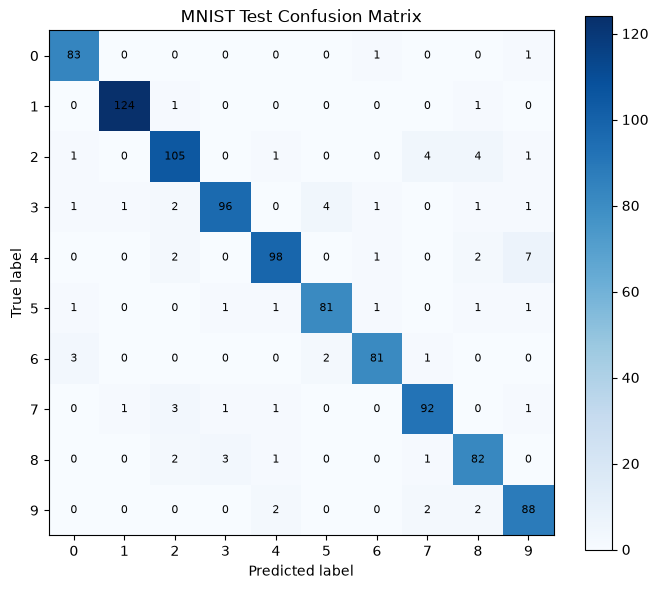

In [77]:
test_predictions = predict(test_images, parameters)
test_accuracy = float(np.mean(test_predictions == test_labels))
assert test_accuracy >= 0.88, "Accuracy is lower than expected. Recheck the TODO functions."
print("Final test accuracy: {:.2%}".format(test_accuracy))

confusion = np.zeros((10, 10), dtype=np.int64)
np.add.at(confusion, (test_labels, test_predictions), 1)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(confusion, cmap="Blues")
ax.set(
    title="MNIST Test Confusion Matrix",
    xlabel="Predicted label",
    ylabel="True label",
    xticks=np.arange(10),
    yticks=np.arange(10),
)
for row in range(10):
    for column in range(10):
        ax.text(column, row, confusion[row, column], ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()


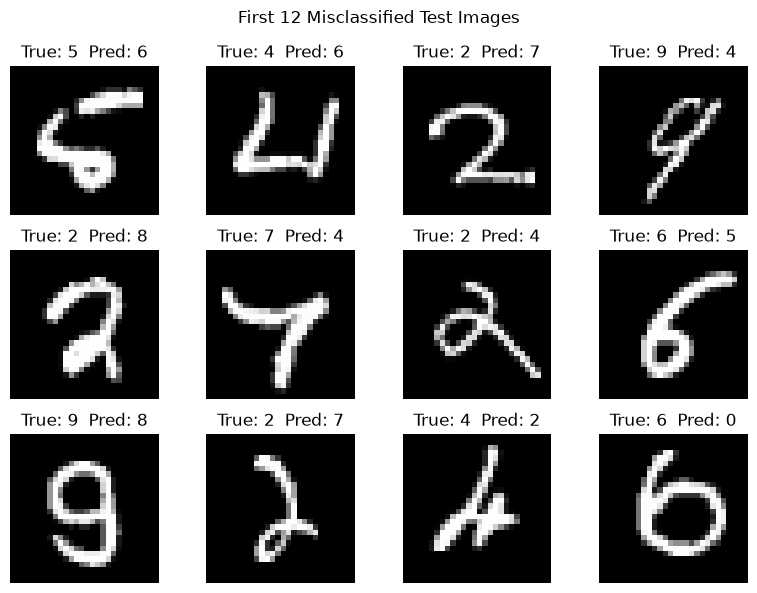

In [78]:
mistake_indices = np.flatnonzero(test_predictions != test_labels)[:12]
fig, axes = plt.subplots(3, 4, figsize=(8, 6))
for ax, index in zip(axes.ravel(), mistake_indices):
    ax.imshow(test_images[index].reshape(28, 28), cmap="gray")
    ax.set_title("True: {}  Pred: {}".format(test_labels[index], test_predictions[index]))
    ax.axis("off")
plt.suptitle("First 12 Misclassified Test Images")
plt.tight_layout()
plt.show()


## Optional extension

Change **one factor at a time** and compare validation accuracy and training time:

- replace the hidden sizes with `[150, 50]`;
- try learning rates `0.03`, `0.12`, and `0.30`;
- train without L2 regularization;
- implement early stopping based on validation accuracy.

Do not use the test set to select these settings.
